In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

Изучим оба датасета по-отдельности.

In [22]:
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

print(f'nulls:{red.isna().sum()}')
print(f'duplicates:{red.duplicated().sum()}')
display(red.describe())

nulls:fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
duplicates:240


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [23]:
print(f'nulls:{white.isna().sum()}')
print(f'duplicates:{white.duplicated().sum()}')
display(white.describe())

nulls:fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
duplicates:937


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


Заметим главные различия: 
1. У красного вина quality в [3, 8], а у белого в [3, 9]
2. Volatile acidity, residual sugar, density, alcohol у red и white заметно разнятся.

Чтобы обучаемые модели не "путались", при склекйке датасетов в единый, необходимо добавить новый признак wine type.

Удалим дупликаты и склеим датасеты в единый.

In [ ]:
red = red.drop_duplicates().reset_index(drop=True)
white = white.drop_duplicates().reset_index(drop=True)

red["wine_type"] = 0
white["wine_type"] = 1

data = pd.concat([red, white], axis=0, ignore_index=True)
print(data.shape)
print(data["wine_type"].value_counts())
print(data["quality"].value_counts().sort_index())

(5320, 13)
wine_type
1    3961
0    1359
Name: count, dtype: int64
quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


Разделим датасет на тренировачные и тестовые данные, построим гистограмму для целевой переменной. Значение test_size было выбрано как 0.2, т.к. размер исходного датасета мал и при больших значениях этого показателя моделям может недоставать данных для обучения и метрики окажутся хуже. Произведем стратификацию по quality и wine_type, чтобы данные попали и в train и test в правильных и честных пропорциях.

<Axes: xlabel='quality', ylabel='Density'>

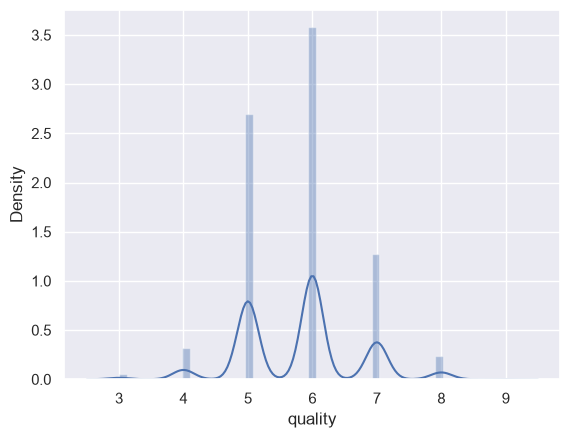

In [80]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data.drop(columns=["quality"]),
    data["quality"],
    test_size=0.2,
    random_state=42,
)
sns.distplot(y_train)

Выбросов в данных не наблюдается. Можно заметить, что строк с quality = 3, 4, 8, 9 очень мало, так что модели вряд ли смогут обучиться отличать такие данные и будут иметь наибольшую ошибку на них. Теперь построим диаграмму корреляций между признаками и целевой переменной.

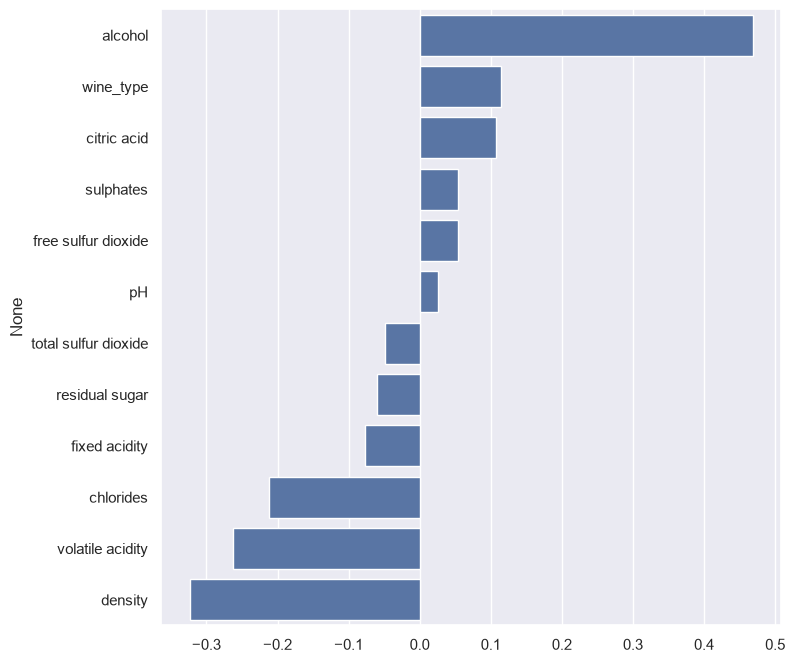

In [81]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations.values)
plot.figure.set_size_inches(8, 8)

Посмотрим на топ-3 признака по модулю значения внимательнее ("alcohol", "density", "volatile acidity"), нарисовав график зависимости целевой переменной от каждого из выделенных признаков (scatter plot) и гистограмму для каждого признака.

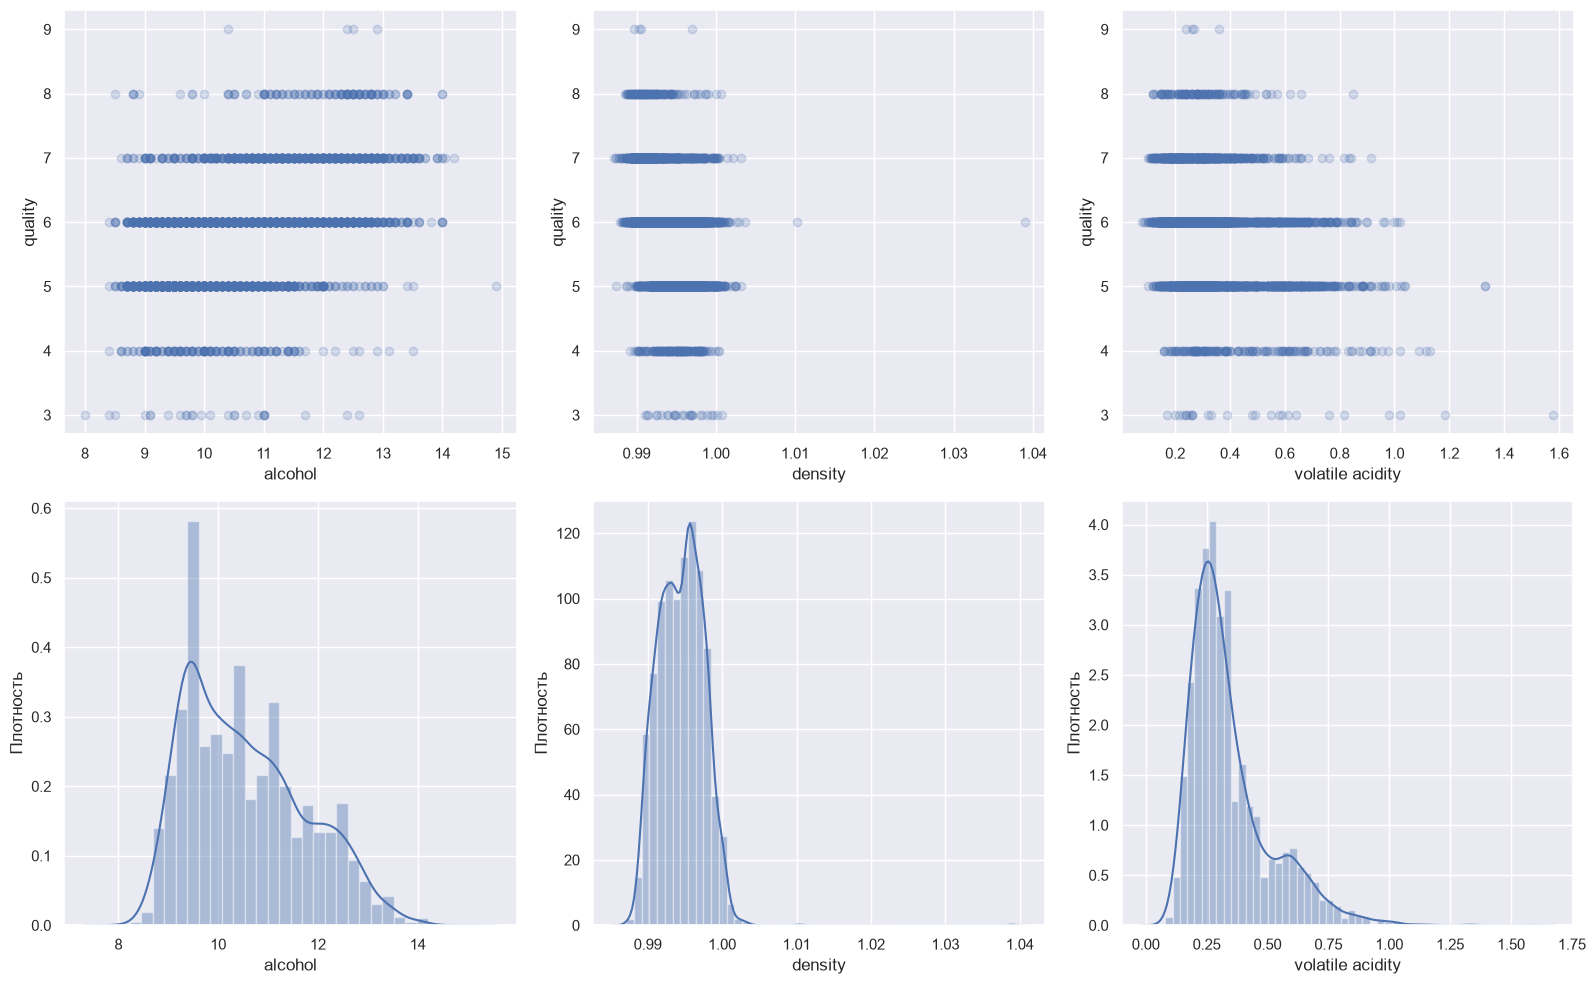

In [82]:
fig, axs = plt.subplots(figsize=(16, 10), nrows=2, ncols=3)
for i, feature in enumerate(["alcohol", "density", "volatile acidity"]):
    axs[0, i].scatter(X_train[feature], y_train, alpha=0.2)
    axs[0, i].set_xlabel(feature)
    axs[0, i].set_ylabel("quality")

for i, feature in enumerate(["alcohol", "density", "volatile acidity"]):
    sns.distplot(X_train[feature], ax=axs[1, i])
    axs[1, i].set_xlabel(feature)
    axs[1, i].set_ylabel("Плотность")
plt.tight_layout()

Очень слабая линейность замечена лишь на графике для alcohol, более высокому качеству соответствует чуть большее содержание алкоголя, однако разброс слишком велик. Density сосредоточена в узком диапазоне, распределние почти равномерно, однако заметна слабая тенденция к ухудшению качества вина при более высоких показателях density, присутствуют выбросы. Подобное происходит и с volatile acidity (VA): более высокие значения quality "стянуты" к меньшему VA, более высокие показатели VA у вин с меньшей оценкой.

Так как линейность почти отсутствует, то LinearRegression, вероятно, окажется неэффективной для данного датасета.

Построим тепловую матрицу корреляции между всеми признаками для отслеживания мультиколлинеарности.

Text(0.5, 1.0, 'Correlation matrix')

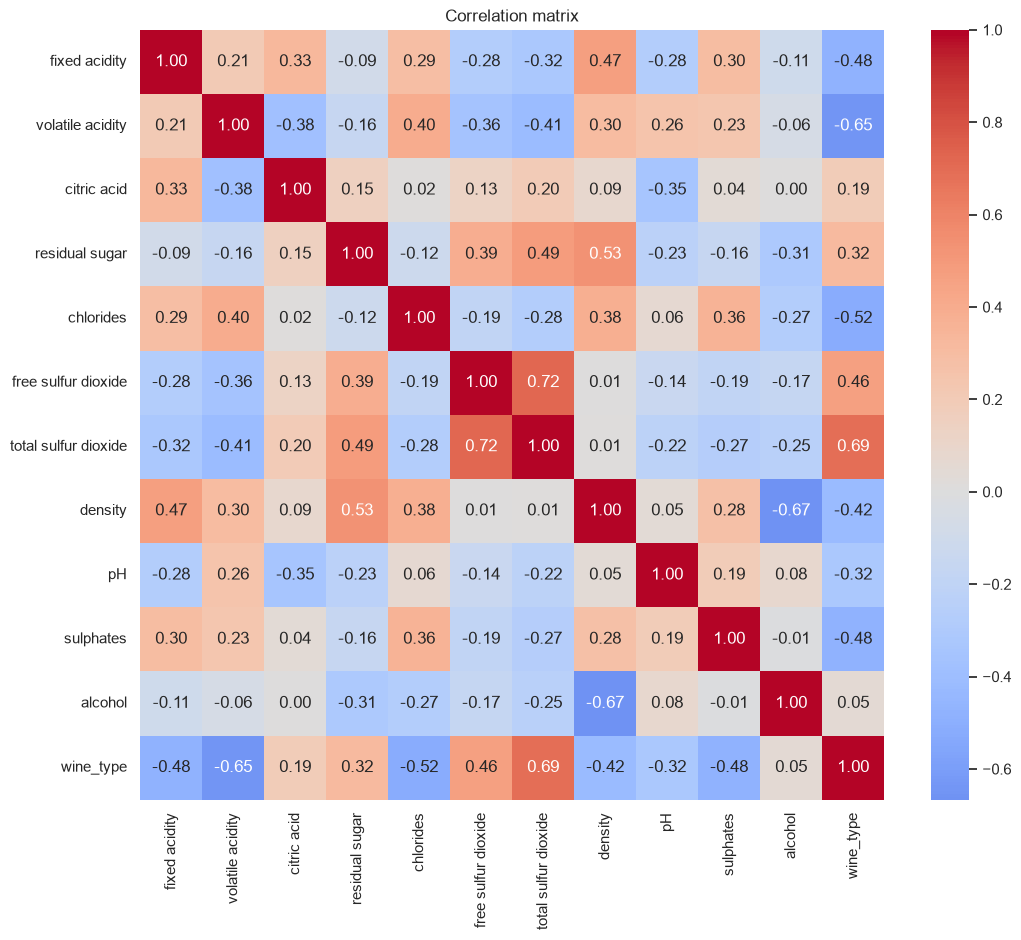

In [83]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")

Видим, что группа {fixed acidity / alcohol / residual sugar / density} мультиколлинеарна: |corr| > 0.5 в большинстве пар. Это помешает обучению LinearRegression, т.к. коэффициенты регрессии могут стать нестабильными, хотя итоговый результат может оказаться приемлемым по оценке. Для всех моделей мультиколлинеарность затруднит интерпретацию их коэффициентов.  

Обучим DummyRegressor в качестве baseline.

In [84]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)
print("Baseline RMSE:", root_mean_squared_error(y_test, pred_base))
print("Baseline MAE:", mean_absolute_error(y_test, pred_base))

Baseline RMSE: 0.8675790772750018
Baseline MAE: 0.6942255780428516


Обучим модель линейной регрессии и посмотрим на получившиеся веса признаков, а также на величины коэффициентов. 

Test RMSE = 0.7207918943170087
Test MAE = 0.5601999396811512


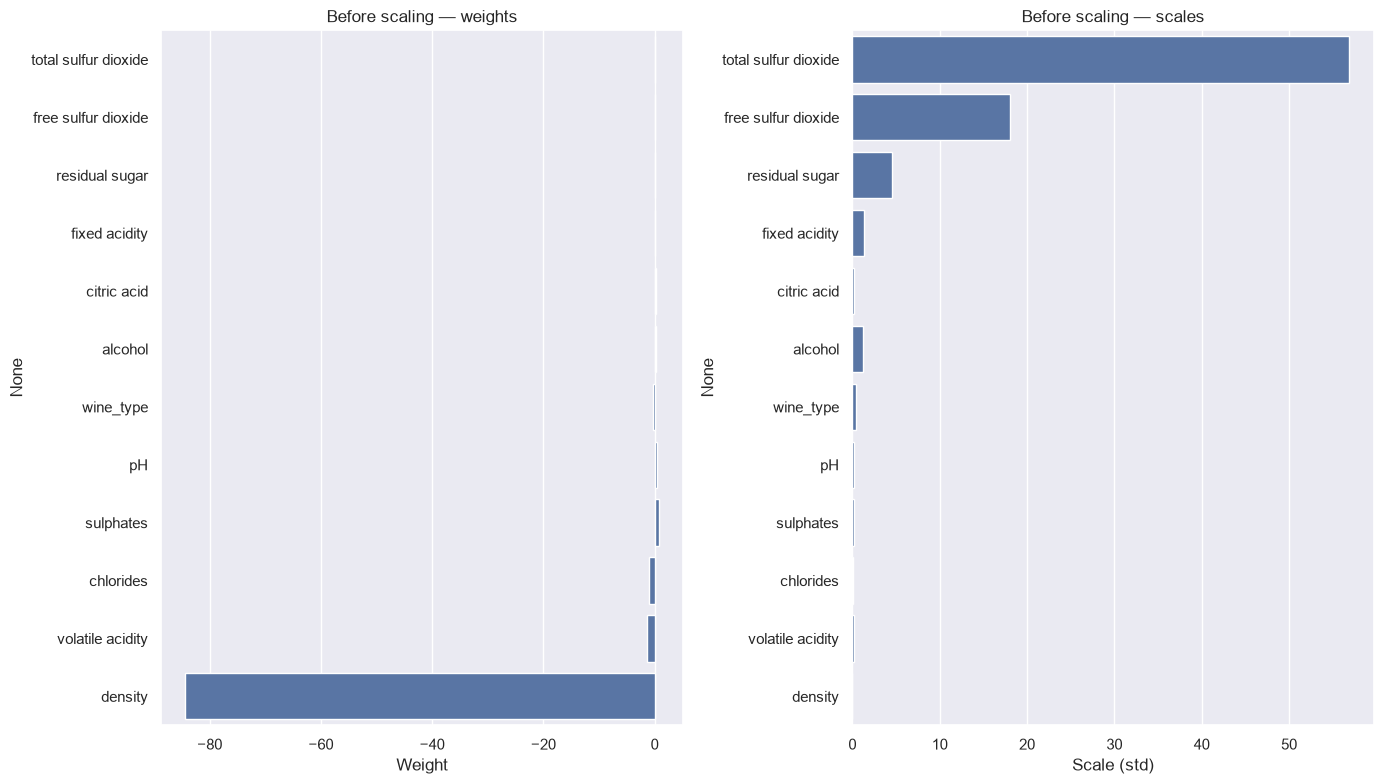

In [85]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

lr_raw = LinearRegression().fit(X_train, y_train)
coef_raw = pd.Series(lr_raw.coef_, index=X_train.columns)
scale_raw = X_train.std()

def show_weights_and_scales(weights, scales, title):
    order = weights.abs().sort_values().index
    w = weights[order]
    s = scales[order]

    fig, axs = plt.subplots(figsize=(14, 8), ncols=2)
    sns.barplot(x=w.values, y=w.index, ax=axs[0])
    axs[0].set_xlabel("Weight")
    axs[0].set_title(f"{title} — weights")

    sns.barplot(x=s.values, y=s.index, ax=axs[1])
    axs[1].set_xlabel("Scale (std)")
    axs[1].set_title(f"{title} — scales")

    plt.tight_layout()
    plt.show()

y_pred = lr_raw.predict(X_test)

print("Test RMSE =", root_mean_squared_error(y_test, y_pred))
print("Test MAE =", mean_absolute_error(y_test, y_pred))

show_weights_and_scales(coef_raw, scale_raw, "Before scaling")

Коэффициенты без масштабирования несопоставимы между признаками: у density вес < −80, у total sulfur dioxide ~ 0 - это следствие разных масштабов, а не важности. Поэтому в Pipeline следует добавить StandardScaler, который делает коэффициенты сравнимыми.

In [91]:
from sklearn.pipeline import Pipeline

linear_regression_pipeline = Pipeline([
    ('scaling', StandardScaler()),
    ('regression', LinearRegression())
])

model = linear_regression_pipeline.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

print("Train RMSE =", root_mean_squared_error(y_train, y_train_pred))
print("Test RMSE =", root_mean_squared_error(y_test, y_pred))
print("Test MAE =", mean_absolute_error(y_test, y_pred))


Train RMSE = 0.7327675755939742
Test RMSE = 0.7207918943170084
Test MAE = 0.5601999396811509


Полученный результат неудовлетворительный: RMSE оценка не попадает в требование < 0.7. Это может быть вызвано дискретностью целевой переменной.

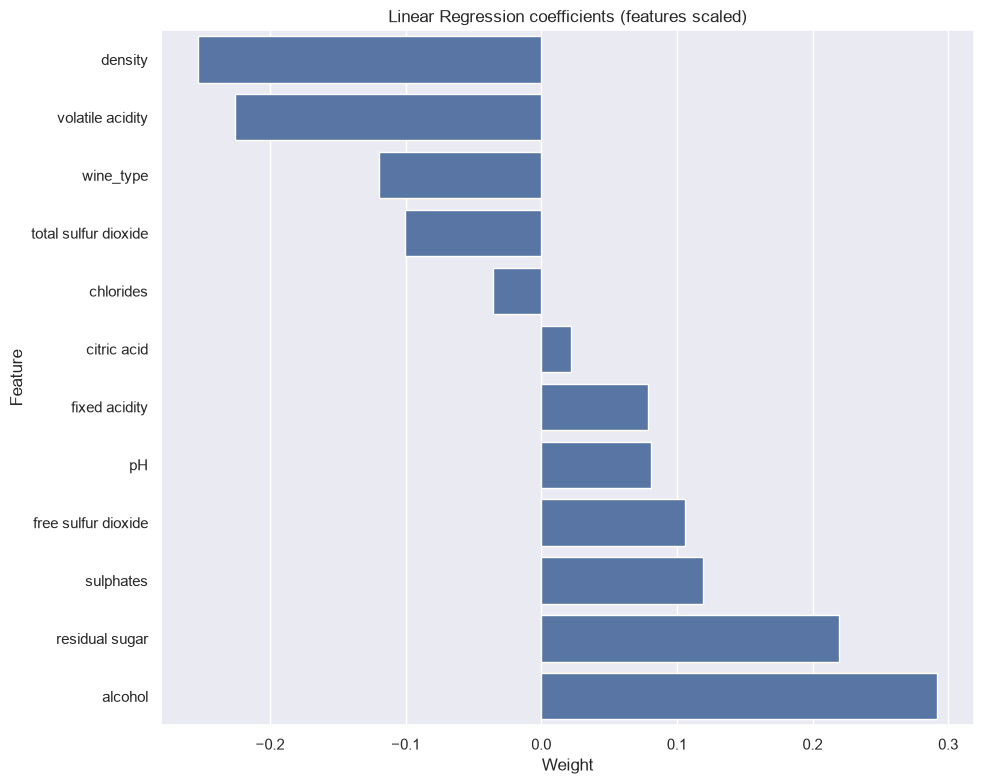

In [89]:
coef = pd.Series(model.named_steps["regression"].coef_, index=X_train.columns)
coef_sorted = coef.sort_values()
plt.figure(figsize=(10, 8))
sns.barplot(x=coef_sorted.values, y=coef_sorted.index)
plt.xlabel("Weight")
plt.ylabel("Feature")
plt.title("Linear Regression coefficients (features scaled)")
plt.tight_layout()

Коэффициенты всё равно не совпадают с корреляциями: коэффициент - это частный эффект при фиксированных остальных, корреляция - попарный. Например, residual sugar имеет довольно высокий вес в модели (>0.20), хотя его прямая корреляция с качеством обычно близка к нулю. Это происходит из-за его сильной связи с density (0.53) и alcohol (-0.31): когда модель замечает влияние плотности и спирта, скрытый положительный вклад от residual sugar становится явным. 

Причина большинства различий между весами и коэфициентом прямой корреляции в мультиколлинеарности. Модель "распределяет" общий эффект между связанными признаками, оставляя некоторым лишь крошечную долю, а другим повышая значимость.

Ни коэффициенты, ни feature importance не доказывают причинность: они описывают использование признаков моделью, а не их влияние на цель.

Теперь обучим RandomForest. Для RandomForest и GradientBoosting (далее) масштабирование можно не выполнять, т.к. данные модели не чувствительны к разницам величин между признаками.

In [94]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_train_pred_rf = rf.predict(X_train)

print("RF Train RMSE =", root_mean_squared_error(y_train, y_train_pred_rf))
print("RF Test RMSE  =", root_mean_squared_error(y_test, y_pred_rf))
print("RF Test MAE   =", mean_absolute_error(y_test, y_pred_rf))



RF Train RMSE = 0.25939304335284247
RF Test RMSE  = 0.6638877860611708
RF Test MAE   = 0.5081766917293233


Результат по метрике RMSE для Test получен удовлетворяющий условию RMSE < 0.7 и заметно лучший чем у модели LinearRegression, т.к. корреляции признаков и цели не назвать линейными. Однако заметим, что разрыв между RMSE на Train и RMSE на Test > 0.4, что свидетельствует о переобучении модели.

In [99]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
y_train_pred_gb = gb.predict(X_train)

print("GB Train RMSE =", root_mean_squared_error(y_train, y_train_pred_gb))
print("GB Test RMSE  =", root_mean_squared_error(y_test, y_pred_gb))
print("GB Test MAE   =", mean_absolute_error(y_test, y_pred_gb))

GB Train RMSE = 0.642578925646506
GB Test RMSE  = 0.6859516515114296
GB Test MAE   = 0.5283206736148577


Аналогично для GradientBoosting: результат удовлетворительный, разрыв у RMSE по Train и Test минимален, переобучения не наблюдается.

Хотя значение RMSE у RandomForest выполняет требования лабораторной работы, для чистоты эксперимента, попробуем устранить переобучение на Train при помощи Grid Search.

In [117]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "max_depth": [5, 10, 13],
    "min_samples_leaf": [3, 5, 7],
    "n_estimators": [100, 200, 300, 400],
}


rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    rf_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)


print("RF best params:", rf_search.best_params_)

RF best params: {'max_depth': 13, 'min_samples_leaf': 3, 'n_estimators': 400}


Для RandomForest были выбраны такие параметры как:
1. max_depth - максимальная глубина каждого дерева. Без ограничения (None) дерево построит максиально подробные правила и запомнит Train.
2. min_samples_leaf - устанавливает минимальное количество объектов в листе. Стандартное значение 1 - буквально запоминание, при больших значениях дерево будет обобщать и действительно предсказывать.
3. n_estimators - количество деревьев "в лесу". Почти не влияет на переобучение, но обеспечивает стабильность результата.

In [118]:
rf_best = rf_search.best_estimator_

rows = []
for name, model in [("RF tuned", rf_best)]:
    tr = root_mean_squared_error(y_train, model.predict(X_train))
    te = root_mean_squared_error(y_test,  model.predict(X_test))
    ma = mean_absolute_error(y_test, model.predict(X_test))
    rows.append({"Модель": name, "Train RMSE": tr, "Test RMSE": te,
                 "Test MAE": ma, "Разрыв": te - tr})

pd.DataFrame(rows)

,Модель,Train RMSE,Test RMSE,Test MAE,Разрыв
0,RF tuned,0.430386,0.668889,0.51443,0.238503


Получилось сократить разрыв: RandomForestRegressor сохраняет достаточно большую разницу между Train и Test, однако она стала более чем в 1.5 раза меньше (0.40 против 0.23). При иных параметрах можно добиться меньшего разрыва, но модель начинает быстро терять в оценке RMSE на test. Разрыв сохраняется из-за бедного разнообразия значения целевой переменной.

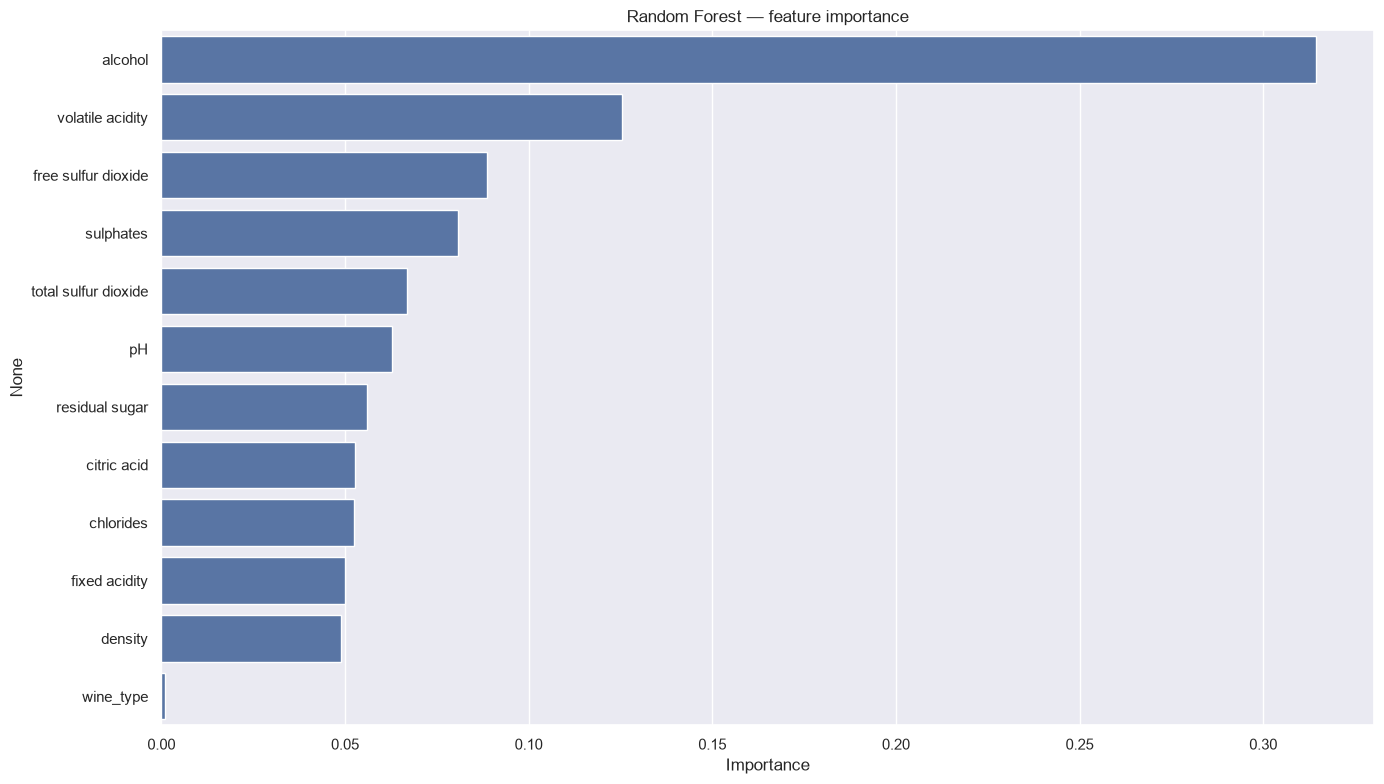

RF top-5: ['alcohol', 'volatile acidity', 'free sulfur dioxide', 'sulphates', 'total sulfur dioxide']


In [126]:
rf_imp = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, axs = plt.subplots(figsize=(14, 8), ncols=1)

sns.barplot(x=rf_imp.values, y=rf_imp.index, ax=axs)
axs.set_title("Random Forest — feature importance")
axs.set_xlabel("Importance")

plt.tight_layout()
plt.show()

print("RF top-5:", list(rf_imp.head(5).index))


Сравним с линейной регрессией.

Совпадения: alcohol - наибольший положительный коэффициент и в RandomForest (RF), и в линейной регрессии (LR), а volatile acidity - второй по важности в RF и второй по модулю коэффициент в LR (отрицательный). Различия: в RF высокие позиции занимают free sulfur dioxide, sulphates и total sulfur dioxide, которые в LR имеют умеренные веса, тогда как в LR очень высокие веса у density, residual sugar и wine_type, но в RF они не входят в топ-5.

Причины расхождений - мультиколлинеарность: density сильно коррелирует с alcohol и residual sugar, поэтому линейная модель делит эффект между ними, а RandomForest использует alcohol и не нуждается в density. Аналогично wine_type связан с volatile acidity и total sulfur dioxide, и его роль в RF перераспределяется. Деревья также улавливают нелинейности, а важность в RF может завышаться для признаков с многими уникальными значениями. Итог: RF подтверждает ключевую роль alcohol и volatile acidity, добавляя free sulfur dioxide, sulphates и total sulfur dioxide; LR из-за мультиколлинеарности даёт нестабильные веса density, residual sugar и wine_type.

Сравним по RMSE и MAE все обученные модели

In [119]:
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
pred = baseline.predict(X_test)

linreg = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression()),
]).fit(X_train, y_train)

models = {
    "Baseline":           baseline,
    "Linear Regression":  linreg,
    "Random Forest":      rf_search.best_estimator_,
    "Gradient Boosting":  gb,
}

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        "Модель": name,
        "RMSE": round(root_mean_squared_error(y_test, pred), 4),
        "MAE":  round(mean_absolute_error(y_test, pred), 4),
    })

pd.DataFrame(rows)

,Модель,RMSE,MAE
0,Baseline,0.8676,0.6942
1,Linear Regression,0.7208,0.5602
2,Random Forest,0.6689,0.5144
3,Gradient Boosting,0.6860,0.5283


Лишь две из трех обученных моделей превзошли Baseline и прошли порог RMSE < 0.70. Лучшей по обоим метрикам RMSE и MAE оказалась модель RandomForestRegressor, однако GradientBoostingRegressor отстает немного. LinearRegression уступает обоим деревьям, не проходя установленный порог RMSE < 0.7, что можно было ожидать, т.к. связи параметров датасета с целевой quality практически нелинейные, с мультиколлинеарностью, и их плохо ловит линейная модель. Еще одна пробема - дискретность целевой переменной, поэтому модель, предсказывающая непрерывные числа, почти всегда получает ошибку. На небольшом датасете с дискретной целевой переменной преимущество среди алгоритмов с деревьями минимальны.

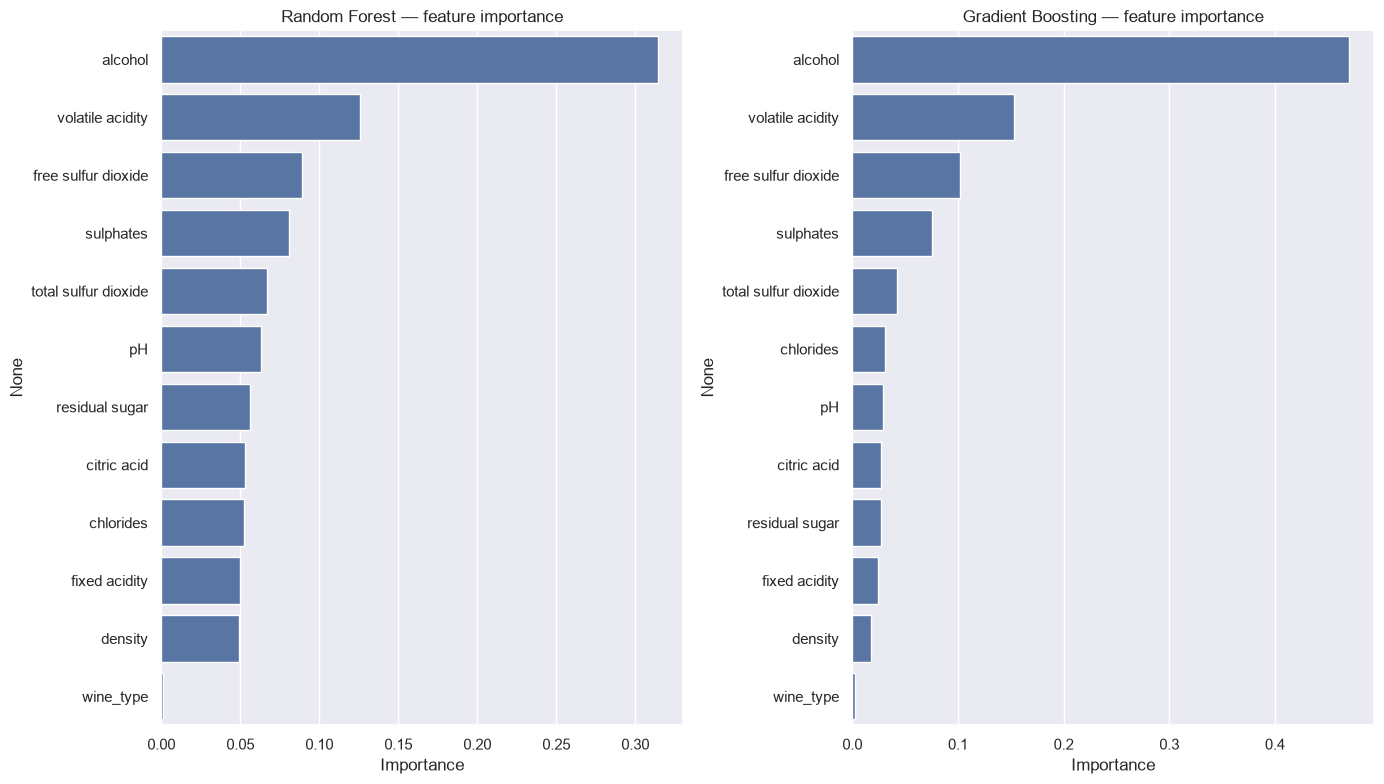

RF top-5: ['alcohol', 'volatile acidity', 'free sulfur dioxide', 'sulphates', 'total sulfur dioxide']
GB top-5: ['alcohol', 'volatile acidity', 'free sulfur dioxide', 'sulphates', 'total sulfur dioxide']


In [121]:
rf_imp = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)
gb_imp = pd.Series(gb.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, axs = plt.subplots(figsize=(14, 8), ncols=2)

sns.barplot(x=rf_imp.values, y=rf_imp.index, ax=axs[0])
axs[0].set_title("Random Forest — feature importance")
axs[0].set_xlabel("Importance")

sns.barplot(x=gb_imp.values, y=gb_imp.index, ax=axs[1])
axs[1].set_title("Gradient Boosting — feature importance")
axs[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()

print("RF top-5:", list(rf_imp.head(5).index))
print("GB top-5:", list(gb_imp.head(5).index))

Топ-1 признак совпал с исследуемыми на корреляцию с target quality, также топ-2 признак volatile acidity в начальном изучении датасета также был одним из самых коррелированных с целевой переменной, однако информативность большинства признаков, отличилась от значений при иследовании датасета, причиной этому является их мультиколлинеарность, из-за этого и произошло "перераспределение" importance между элементами группы. Тем не менее, в совокупности эти группы признаков остаются сильными для моделей. Совпадение топ-5 по важности признаков между двумя моделями свидетельствует об устойчивости выделенных признаков.

На основании feature importance нельзя утверждать, что изменение признака является причиной изменения quality. Feature importance показывает, насколько модель использует признак для предсказания. Причинно-следственная связь требует эксперимента, например контролируемое изменение признака при фиксированных остальных. Так, высокая важность alcohol не доказывает, что если в вине искусственно поднять спирт, качество вырастет - это лишь значит, что модель опирается на alcohol при построении прогноза.

Проведем анализ ошибок лучшей модели, а именно RandomForestRegressor.

Text(0.5, 0, 'error')

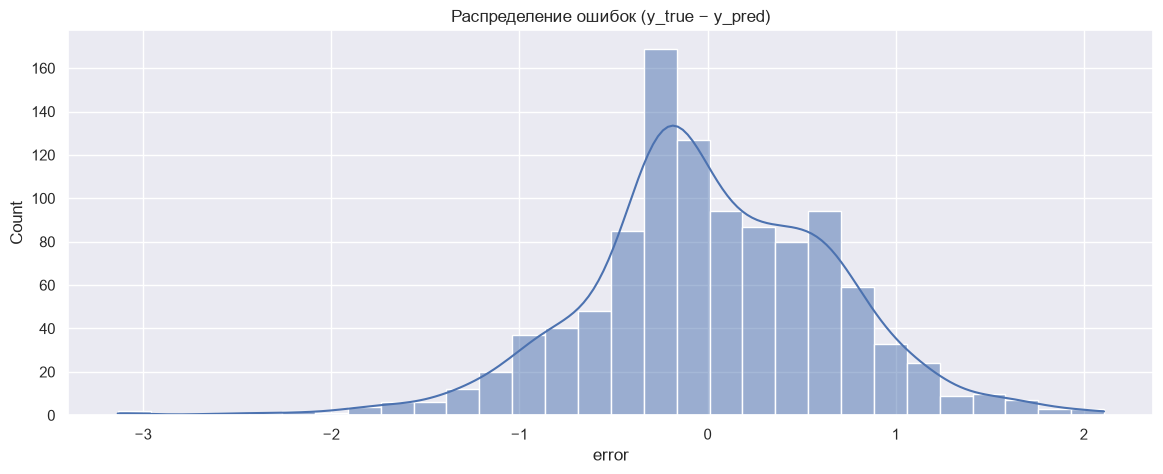

In [122]:
best_model = rf_best
y_pred_best = best_model.predict(X_test)
errors = y_test - y_pred_best
abs_errors = np.abs(errors)

fig, axs = plt.subplots(figsize=(14, 5), ncols=1)
sns.histplot(errors, bins=30, kde=True, ax=axs)
axs.set_title("Распределение ошибок (y_true − y_pred)")
axs.set_xlabel("error")

In [123]:
err_df = pd.DataFrame({
    "y_true": y_test.values,
    "y_pred": np.round(y_pred_best, 2),
    "error": errors.values,
    "abs_error": abs_errors.values,
}, index=y_test.index)

top_errors = err_df.sort_values("abs_error", ascending=False).head(10)
print(top_errors)

      y_true  y_pred     error  abs_error
4151       3    6.14 -3.135237   3.135237
1729       3    6.08 -3.080091   3.080091
4404       4    6.61 -2.610608   2.610608
718        3    5.43 -2.434382   2.434382
2057       4    6.25 -2.247284   2.247284
4423       4    6.13 -2.126680   2.126680
2077       8    5.89  2.107860   2.107860
3456       8    5.91  2.091441   2.091441
4652       8    5.98  2.018354   2.018354
1253       3    4.99 -1.986207   1.986207


Из топа объектов с самыми большимы ошибками видно, что модель ошиается чаще всего на самых редких данных: строки со значениями quality 3, 4, 8. Модели не хватило информации датасета, чтобы научиться достаточно точно их распознавать. Это совпало с ожиданиями при первоначальном анализе данных.

In [124]:
err_by_quality = err_df.groupby("y_true").agg(
    count=("abs_error", "size"),
    mean_abs_error=("abs_error", "mean"),
    max_abs_error=("abs_error", "max"),
    mean_pred=("y_pred", "mean"),
).round(3)
print(err_by_quality)

        count  mean_abs_error  max_abs_error  mean_pred
y_true                                                 
3           4           2.659          3.135      5.660
4          38           1.316          2.611      5.316
5         348           0.441          1.871      5.414
6         458           0.372          1.303      5.859
7         190           0.646          1.735      6.361
8          25           1.516          2.108      6.485
9           1           1.905          1.905      7.090


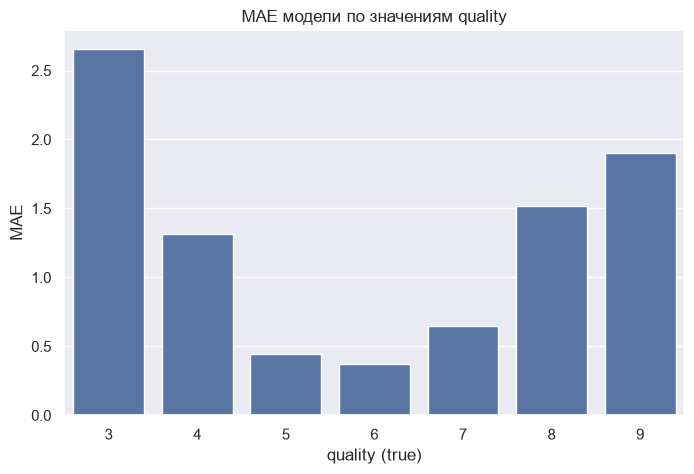

In [125]:
plt.figure(figsize=(8, 5))
sns.barplot(x=err_by_quality.index, y=err_by_quality["mean_abs_error"])
plt.xlabel("quality (true)")
plt.ylabel("MAE")
plt.title("MAE модели по значениям quality")
plt.show()

На редких quality (3, 9) MAE существенно выше, чем на массовых (5, 6, 7). Это ожидаемо по трём причинам:
1. В train мало примеров с quality = 3 и quality = 9, модель не выучивает их профиль.
2. Деревья в листьях усредняют - редкие значения "размываются" ближе к среднему.
3. quality - дискретная переменная, а модель предсказывает непрерывные значения. например, при истинном значении 3 модель даёт 3.5-4, ошибка >= 0.5, а при истинном 8 - 7.0-7.5, ошибка >= 0.5. Это структурный предел алгоритма.